# Schritt 4: Modellbildung

**Ziel dieses Notebooks:** das in Schritt 3 gewählte Modell (GLM, Poisson × Gamma) auf dem ganzen Trainingsteil
trainieren, seine Güte einmal auf dem Testteil messen, zeigen, welche Variablen und Zusammenhänge relevant sind, und
daraus einen fairen Jahresbeitrag pro Kunde berechnen. Das Gradient-Boosting-Modell läuft als Vergleich mit.

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import PoissonRegressor, GammaRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_tweedie_deviance, d2_tweedie_score

pd.set_option("display.width", 200)   # show wide tables without cutting columns

## 1. Daten laden und das finale Modell trainieren

In [2]:
# model table from step 2
df = pd.read_parquet("../data/model_data.parquet")
train = df[df["split"] == "train"]
test = df[df["split"] == "test"]
print("training part:", len(train), "contracts | test part:", len(test), "contracts")

training part: 542410 contracts | test part: 135603 contracts


The model definitions and metrics are the same as in step 3 (sections 2 and 3), copied unchanged:

In [3]:
# GLM input: one 0/1 column per band or category level (the first level is the reference)
glm_cols = ["BonusMalusBand", "DrivAgeBand", "VehAgeBand", "VehPowerBand", "Area", "Region", "VehBrand", "VehGas"]

def glm_input(d):
    return pd.get_dummies(d[glm_cols], drop_first=True, dtype=float)

# GBM input: the raw values; the trees find the cut points themselves
gbm_cols = ["BonusMalus", "DrivAge", "VehAge", "VehPower", "Density", "Region", "VehBrand", "VehGas"]

def gbm_input(d):
    return d[gbm_cols]

# gradient boosting with modest, fixed settings (no tuning)
def boosting(loss, min_leaf):
    return HistGradientBoostingRegressor(loss=loss, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=min_leaf,
                                         l2_regularization=1.0, max_iter=1000, early_stopping=True,
                                         validation_fraction=0.1, n_iter_no_change=30,
                                         categorical_features="from_dtype", random_state=42)

def fit(kind, d):
    # frequency on all contracts (weight = exposure), severity on the contracts with a claim (weight = number of claims)
    if kind == "GLM":
        X = glm_input(d)
        freq = PoissonRegressor(alpha=0, solver="newton-cholesky", tol=1e-6)   # maximum likelihood, no penalty
        sev = GammaRegressor(alpha=0, solver="newton-cholesky", tol=1e-6)
    else:
        X = gbm_input(d)
        freq = boosting("poisson", 500)
        sev = boosting("gamma", 50)
    c = d["has_claim"].to_numpy()
    freq.fit(X, d["Frequency"], sample_weight=d["Exposure"])
    sev.fit(X[c], d["Severity"][c], sample_weight=d["claim_rows"][c])

    # balance: on the data it was fitted on, the model reproduces the total number of claims and the total claim cost
    k_freq = d["claim_rows"].sum() / (freq.predict(X) * d["Exposure"]).sum()
    k_sev = d["ClaimAmountCapped"][c].sum() / (sev.predict(X[c]) * d["claim_rows"][c]).sum()
    return {"kind": kind, "freq": freq, "sev": sev, "k_freq": k_freq, "k_sev": k_sev}

def predict(m, d):
    # expected capped claim cost per contract-year = frequency x severity
    X = glm_input(d) if m["kind"] == "GLM" else gbm_input(d)
    return m["k_freq"] * m["freq"].predict(X) * m["k_sev"] * m["sev"].predict(X)

def gini(y, mu, w):
    # Lorenz curve: contracts sorted from the lowest to the highest prediction
    order = np.argsort(np.asarray(mu))
    y, w = np.asarray(y)[order], np.asarray(w)[order]
    share_exposure = np.concatenate([[0], np.cumsum(w) / w.sum()])
    share_cost = np.concatenate([[0], np.cumsum(y * w) / (y * w).sum()])
    return 1 - 2 * np.trapezoid(share_cost, share_exposure)

def scores(d, mu, target="PurePremiumCapped"):
    y, w = d[target], d["Exposure"]
    return {"deviance": mean_tweedie_deviance(y, mu, sample_weight=w, power=1.5),
            "D2": d2_tweedie_score(y, mu, sample_weight=w, power=1.5),
            "gini": gini(y, mu, w) if np.ptp(mu) > 0 else np.nan,    # a constant premium does not sort anybody
            "predicted/actual": (mu * w).sum() / (y * w).sum()}

In [4]:
# the final model (GLM) and the benchmark (GBM), both fitted on the whole training part
glm = fit("GLM", train)
gbm = fit("GBM", train)
for m in [glm, gbm]:
    print(m["kind"], "| balance factors: frequency", round(m["k_freq"], 4), "| severity", round(m["k_sev"], 4))

GLM | balance factors: frequency 1.0 | severity 0.9999
GBM | balance factors: frequency 1.0029 | severity 1.0433


**Findings**

Both models are fitted once on the whole training part (542,410 contracts) with the settings of step 3. The balance
factors are similar to the cross-validation: 1.0 and 0.9999 for the GLM, 1.0029 and 1.0433 for the GBM (for its severity
part the actual claim cost is again higher than its prediction on its own fitting data, by about 4 %, a little less than
the 5.6–7.8 % in the folds of step 3).

## 2. Großschadenzuschlag

In [5]:
# the cost above the cap is spread over all customers as one factor, estimated on the training part
loading = train["ClaimAmount"].sum() / train["ClaimAmountCapped"].sum()
print("large-claim loading (training part):", round(loading, 4))
print("the same ratio in the test part:", round(test["ClaimAmount"].sum() / test["ClaimAmountCapped"].sum(), 4))
print("largest claim amount of a contract: training part", round(train["ClaimAmount"].max()),
      "| test part", round(test["ClaimAmount"].max()))

large-claim loading (training part): 1.2573
the same ratio in the test part: 1.0458
largest claim amount of a contract: training part 4075401 | test part 276643


**Findings**

* The models predict the capped cost. The cost above 100,000 per claim is added back with one uniform factor for all
  customers, the **large-claim loading 1.2573** = total cost / capped cost, estimated on the training part only.
* In the test part the same ratio is only 1.0458: 36 of the 41 contracts with a claim above the cap are in the
  training part (step 2), including the largest claim amount (4,075,401); the largest claim amount of a test contract
  is 276,643.
* So the loading rests on very few claims and is uncertain; with one year of data it cannot be estimated much better
  (section 8). Training and test part are random samples of the same year, so the difference is chance, not a change
  over time.

## 3. Güte des finalen Modells auf dem Testteil

In [6]:
# predictions for the test part: capped claim cost per contract-year
mu = {"Constant": np.full(len(test), np.average(train["PurePremiumCapped"], weights=train["Exposure"])),
      "GLM": predict(glm, test),
      "GBM": predict(gbm, test)}

print("capped claims (what the models were fitted on):")
print(pd.DataFrame({name: scores(test, p) for name, p in mu.items()}).T.round(4), "\n")

# the target: uncapped cost per year, against prediction x large-claim loading
print("uncapped claims, prediction x loading:")
print(pd.DataFrame({name: scores(test, p * loading, target="PurePremium") for name, p in mu.items()}).T.round(4))

capped claims (what the models were fitted on):
          deviance      D2    gini  predicted/actual
Constant   77.7072 -0.0000     NaN            0.9996
GLM        73.9925  0.0478  0.3133            1.0031
GBM        73.3832  0.0556  0.3302            1.0048 

uncapped claims, prediction x loading:
          deviance      D2    gini  predicted/actual
Constant   80.1965 -0.0051     NaN            1.2017
GLM        75.9489  0.0482  0.3290            1.2060
GBM        75.5435  0.0532  0.3378            1.2080


**Findings** (test part: 135,603 contracts that no model has seen)

| capped claims | deviance | D² | Gini | predicted / actual |
|---|---|---|---|---|
| Constant | 77.707 | 0.00 % | – | 1.000 |
| **GLM (final model)** | 73.992 | 4.78 % | 0.313 | 1.003 |
| GBM (benchmark) | 73.383 | 5.56 % | 0.330 | 1.005 |

* The final GLM explains 4.78 % of the deviance on unseen contracts, a little less than in the cross-validation of
  step 3 (5.08 %), sorts the customers with a Gini of 0.313, and gets the overall level right (predicted / actual
  1.003). The GBM is again more accurate, by 0.61 in deviance.
* **On the uncapped target** (uncapped cost per year, against prediction × loading): D² 4.82 % for the
  GLM and 5.32 % for the GBM, Gini 0.329 and 0.338. All models, the constant included, predict 20–21 % more than the
  test part actually cost (1.2017–1.2080). This is the large-claim loading (1.2573 in the training part, 1.0458 in the
  test part, section 2), not an error of the models.

In [7]:
# how certain is the difference between GLM and GBM on the test part? bootstrap: draw contracts with replacement
y, w = test["PurePremiumCapped"].to_numpy(), test["Exposure"].to_numpy()
rng = np.random.default_rng(42)
diff = []
for _ in range(1000):
    i = rng.integers(0, len(test), len(test))
    diff.append(mean_tweedie_deviance(y[i], mu["GLM"][i], sample_weight=w[i], power=1.5)
                - mean_tweedie_deviance(y[i], mu["GBM"][i], sample_weight=w[i], power=1.5))
diff = np.array(diff)
print("deviance GLM - GBM: mean", round(diff.mean(), 3), "| 95 % interval", np.percentile(diff, [2.5, 97.5]).round(3),
      "| share of draws in which the GBM is better:", round((diff > 0).mean(), 3))

deviance GLM - GBM: mean 0.624 | 95 % interval [0.045 1.154] | share of draws in which the GBM is better: 0.981


**Findings**

The test part is a sample, so the difference between the two models on it is uncertain. Drawing the 135,603 test
contracts 1,000 times with replacement gives a deviance difference GLM − GBM of 0.624 on average, with a 95 % interval
from 0.045 to 1.154; the GBM is better in 98.1 % of the draws. So the GBM is also more accurate on the test part, but
the advantage is small compared with the gap between the models and the constant (77.707 against 73.992).
This supports the decision of step 3: choosing the transparent and better calibrated GLM costs little accuracy.

## 4. Fairness auf dem Testteil

In [8]:
# actual / predicted per group in the test part: cost for the GLM and the GBM, number of claims for the GLM
check = test[["DrivAgeBand", "BonusMalusBand", "VehAgeBand", "Area", "VehBrand", "Exposure", "claim_rows", "ClaimAmountCapped"]].copy()
check["cost_GLM"] = mu["GLM"] * test["Exposure"]
check["cost_GBM"] = mu["GBM"] * test["Exposure"]
check["claims_GLM"] = glm["k_freq"] * glm["freq"].predict(glm_input(test)) * test["Exposure"]   # predicted number of claims
for col in ["DrivAgeBand", "BonusMalusBand", "VehAgeBand", "Area", "VehBrand"]:
    g = check.groupby(col, observed=True)[["claim_rows", "ClaimAmountCapped", "cost_GLM", "cost_GBM", "claims_GLM"]].sum()
    g["cost GLM"] = g["ClaimAmountCapped"] / g["cost_GLM"]
    g["cost GBM"] = g["ClaimAmountCapped"] / g["cost_GBM"]
    g["claims GLM"] = g["claim_rows"] / g["claims_GLM"]
    print(g[["claim_rows", "cost GLM", "cost GBM", "claims GLM"]].round(2), "\n")

             claim_rows  cost GLM  cost GBM  claims GLM
DrivAgeBand                                            
18-20               115      0.70      0.84        0.86
21-24               262      0.65      0.70        0.90
25-29               435      0.91      0.88        0.96
30-39              1139      1.07      1.07        1.00
40-49              1348      1.12      1.08        1.04
50-59              1117      1.03      1.01        1.00
60-69               524      0.91      0.85        1.08
70+                 358      0.99      1.13        0.99 

                claim_rows  cost GLM  cost GBM  claims GLM
BonusMalusBand                                            
50                    2363      1.00      0.98        1.03
51-60                  725      1.22      1.20        1.01
61-70                  623      1.08      1.01        1.00
71-80                  541      0.94      0.99        0.97
81-90                  354      0.94      0.93        1.04
91-100                 44

       claim_rows  predicted per year  actual per year  actual/predicted
group                                                                   
1             304               52.81            71.37              1.35
2             342               69.98            65.13              0.93
3             383               81.43            68.37              0.84
4             401               92.42            98.56              1.07
5             465              103.98           130.01              1.25
6             453              118.33           112.93              0.95
7             547              138.23           130.22              0.94
8             614              169.00           162.22              0.96
9             731              224.55           259.48              1.16
10           1058              437.55           374.55              0.86


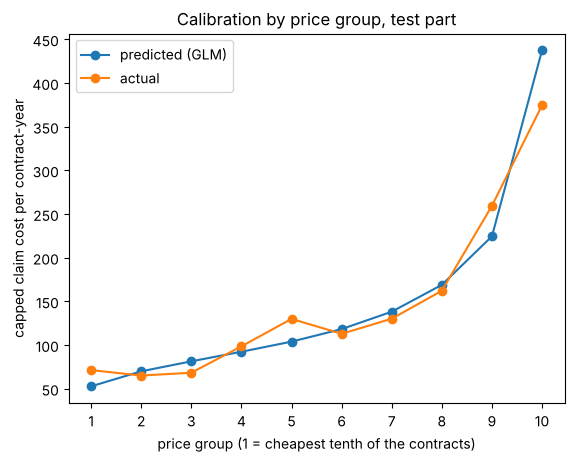

In [9]:
# calibration by price group: ten groups of equal size, from the cheapest to the most expensive prediction
check["group"] = pd.qcut(pd.Series(mu["GLM"], index=test.index).rank(method="first"), 10, labels=range(1, 11))
g = check.groupby("group", observed=True)[["Exposure", "claim_rows", "ClaimAmountCapped", "cost_GLM"]].sum()
g["predicted per year"] = g["cost_GLM"] / g["Exposure"]
g["actual per year"] = g["ClaimAmountCapped"] / g["Exposure"]
g["actual/predicted"] = g["ClaimAmountCapped"] / g["cost_GLM"]
print(g[["claim_rows", "predicted per year", "actual per year", "actual/predicted"]].round(2))

plt.plot(g.index.astype(int), g["predicted per year"], marker="o", label="predicted (GLM)")
plt.plot(g.index.astype(int), g["actual per year"], marker="o", label="actual")
plt.xticks(range(1, 11))
plt.xlabel("price group (1 = cheapest tenth of the contracts)")
plt.ylabel("capped claim cost per contract-year")
plt.title("Calibration by price group, test part")
plt.legend()
plt.show()

**Findings** (actual / predicted on the test part; `claims GLM` compares the number of claims instead of the cost)

* The test part is four times smaller than the training part checked in step 3, so the groups have few claims
  (drivers 18–20: 115, area F: 177, brand B14: 31), and single large claims move the cost ratios a lot.
* **GLM and GBM show nearly the same deviations in the same groups**, for example area F 1.62 / 1.53, drivers 21–24
  0.65 / 0.70, Bonus-Malus 51–60 1.22 / 1.20, brand B12 1.27 / 1.30. A deviation that both models show comes from the
  test sample, not from the choice of the model.
* The **number of claims** agrees much better than the cost: 0.86–1.08 for all age bands, 0.92–1.04 for the
  Bonus-Malus bands and 0.95–1.02 for the vehicle-age bands. Most cost deviations therefore come from the claim sizes.
  The exception is area F, where the test part has 20 % more claims than predicted (1.20).
* The youngest drivers cost less in the test part than both models predict (cost 0.70 for the GLM and 0.84 for the
  GBM; claims 0.86). With 115 claims this ratio is very uncertain. The decision in step 3 rested on the 502 claims of
  the training part (GLM 0.998, GBM 1.284); the test part can neither confirm nor reject it.
* **Price groups:** the predicted cost per year rises in every group, from 52.81 in the cheapest tenth to 437.55 in
  the most expensive one; the actual cost rises overall, from 71.37 to 374.55, but not in every group (chart). Actual / predicted lies between 0.84 and 1.35; the cheapest tenth
  is again too cheap (1.35), as in step 3.

## 5. Welche Variablen sind relevant?

                increase in %    sd
VehBrand                 0.02  0.16
VehGas                   0.13  0.06
VehPowerBand             0.48  0.10
Region                   0.64  0.12
Area                     0.71  0.18
VehAgeBand               0.81  0.30
DrivAgeBand              1.48  0.12
BonusMalusBand           9.10  0.61


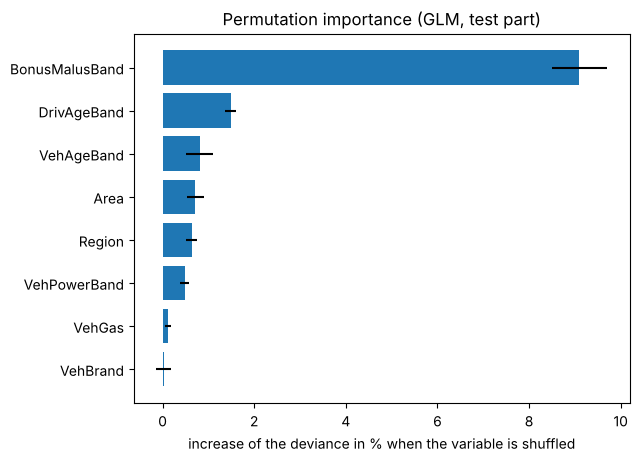

In [10]:
# permutation importance: shuffle one variable in the test part, predict again, how much worse is the deviance?
base = scores(test, mu["GLM"])["deviance"]
importance = {}
for col in glm_cols:
    increase = []
    for seed in range(5):                                   # five different shuffles
        shuffled = test.copy()
        shuffled[col] = test[col].sample(frac=1, random_state=seed).set_axis(test.index)   # same values, random order
        increase.append(100 * (scores(shuffled, predict(glm, shuffled))["deviance"] / base - 1))
    importance[col] = {"increase in %": np.mean(increase), "sd": np.std(increase)}
importance = pd.DataFrame(importance).T.sort_values("increase in %")
print(importance.round(2))

plt.barh(importance.index, importance["increase in %"], xerr=importance["sd"])
plt.xlabel("increase of the deviance in % when the variable is shuffled")
plt.title("Permutation importance (GLM, test part)")
plt.show()

**Findings**

Shuffling a variable destroys its information but keeps its distribution; the more the deviance rises, the more the
premium depends on the variable. Mean of five shuffles, with the standard deviation:

* **Bonus-Malus is by far the most important variable** (+9.10 %), followed by driver age (+1.48 %), vehicle age
  (+0.81 %), area (+0.71 %), region (+0.64 %) and vehicle power (+0.48 %). Fuel type adds little (+0.13 %). The top two
  match the one-way analysis of step 1, where Bonus-Malus and age were the strongest drivers.
* **Brand:** +0.02 % ± 0.16 %, so no measurable effect on the capped cost of the test part. A hint from the fairness
  table above: brand B12 (864 test claims) has as many claims as predicted (1.04) but a higher cost (1.27), so its claims
  in the test part are larger than the model expects. The brand factors (mainly the lower frequency of B12, section 6)
  should therefore be checked with more data.

## 6. Welche Zusammenhänge hat das Modell gelernt? Die Tariffaktoren

        frequency  severity  premium  claims
50           1.00      1.00     1.00    9229
51-60        1.62      1.01     1.64    2851
61-70        2.59      0.96     2.48    2493
71-80        2.46      1.18     2.91    2257
81-90        2.59      1.09     2.82    1366
91-100       4.02      1.21     4.85    1942
101+         7.87      1.10     8.67    1008 



       frequency  severity  premium  claims
18-20       1.23      1.60     1.96     502
21-24       0.79      1.19     0.94    1132
25-29       0.60      1.01     0.60    1810
30-39       0.69      1.03     0.72    4586
40-49       1.00      1.00     1.00    5218
50-59       1.02      1.06     1.08    4506
60-69       0.92      1.03     0.95    1946
70+         0.99      1.36     1.35    1446 

       frequency  severity  premium  claims
0-4         1.00      1.00     1.00    7539
5-9         1.00      0.93     0.93    6413
10-14       0.89      0.89     0.80    5189
15-19       0.73      0.99     0.72    1748
20+         0.60      0.83     0.50     257 

       frequency  severity  premium  claims
4-5         0.96      0.89     0.85    7330
6-7         1.00      1.00     1.00    9483
8-9         1.09      0.92     1.00    2309
10-11       1.19      0.99     1.18    1529
12+         1.18      1.02     1.20     495 



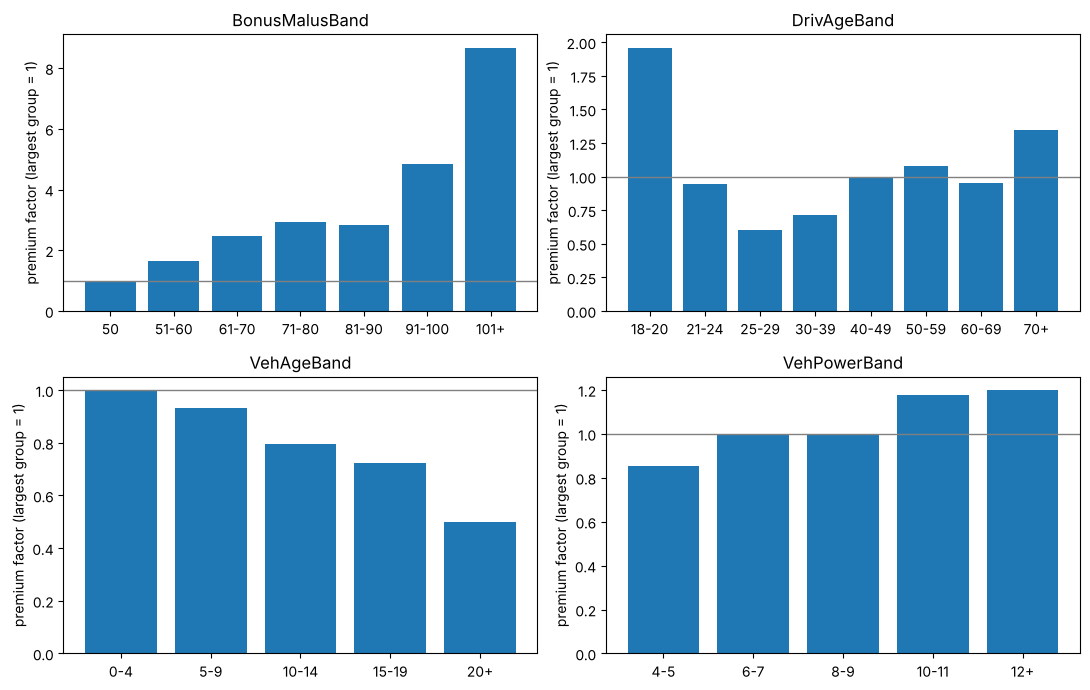

In [11]:
# GLM coefficients; with the log link the factors multiply, so the coefficients of frequency and severity add up
coef = pd.DataFrame({"frequency": glm["freq"].coef_, "severity": glm["sev"].coef_}, index=glm["freq"].feature_names_in_)
coef["premium"] = coef["frequency"] + coef["severity"]

def factors(col):
    # factor = exp(coefficient), one row per level; the level with the largest exposure gets factor 1
    levels = df[col].cat.categories
    tab = pd.DataFrame(0.0, index=levels, columns=coef.columns)     # the first level is the reference (coefficient 0)
    for level in levels[1:]:
        tab.loc[level] = coef.loc[col + "_" + str(level)]
    base_level = train.groupby(col, observed=True)["Exposure"].sum().idxmax()
    tab = np.exp(tab - tab.loc[base_level])
    tab["claims"] = train.groupby(col, observed=True)["claim_rows"].sum()
    return tab

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.flat, ["BonusMalusBand", "DrivAgeBand", "VehAgeBand", "VehPowerBand"]):
    tab = factors(col)
    print(tab.round(2), "\n")
    ax.bar(tab.index.astype(str), tab["premium"])
    ax.axhline(1, color="grey", lw=1)
    ax.set_title(col)
    ax.set_ylabel("premium factor (largest group = 1)")
plt.tight_layout()
plt.show()

**Findings** (factors relative to the largest group of each variable; premium factor = frequency factor × severity
factor)

* **Bonus-Malus:** the premium factor rises from 1.00 (50, the best level) to 1.64 (51–60), 2.48–2.91 (61–90), 4.85
  (91–100) and 8.67 (101+), almost entirely through the frequency (factor 7.87 for 101+). One small dent: 81–90 (2.82)
  lies slightly below 71–80 (2.91); a tariff would smooth it (section 8).
* **Driver age**, on top of Bonus-Malus: drivers aged 18–20 pay 1.96 times as much as those aged 40–49, mainly through
  larger claims (severity factor 1.60, frequency factor 1.23); drivers aged 70+ pay 1.35, also through the severity
  (1.36). Drivers aged 25–39 get factors of 0.60–0.72. My interpretation of the small frequency factor of the youngest:
  the Bonus-Malus already carries most of their higher frequency (the two are correlated, ρ = −0.57, step 1).
* **Vehicle age:** the premium falls steadily from 1.00 (0–4 years) to 0.50 (20+).
* **Vehicle power:** rises slightly, from 0.85 (4–5) to 1.18–1.20 (10 and more).

In [12]:
# the categorical variables
for col in ["Area", "VehGas", "VehBrand", "Region"]:
    print(factors(col).round(2), "\n")

   frequency  severity  premium  claims
A       0.86      1.11     0.95    2705
B       0.94      1.00     0.94    2133
C       1.00      1.00     1.00    5684
D       1.15      1.06     1.22    5170
E       1.22      1.04     1.28    4857
F       1.26      0.80     1.01     597 

         frequency  severity  premium  claims
Diesel        1.16      1.01     1.17   10773
Regular       1.00      1.00     1.00   10373 

     frequency  severity  premium  claims
B1        1.00      1.00     1.00    5526
B10       0.99      0.98     0.97     602
B11       1.21      1.04     1.27     540
B12       0.75      1.00     0.75    3336
B13       1.04      1.15     1.19     436
B14       0.79      0.81     0.64     100
B2        0.99      0.99     0.98    5433
B3        1.05      1.04     1.09    1953
B4        1.01      1.02     1.03     887
B5        1.08      0.97     1.05    1347
B6        1.00      0.86     0.85     986 

     frequency  severity  premium  claims
R11       0.99      0.92     0

**Findings**

* **Area:** the frequency factor rises from A (0.86) to F (1.26), as in step 1. For F the severity factor 0.80 brings
  the premium factor back to 1.01; D and E are the most expensive areas (1.22 and 1.28).
* **Fuel:** Diesel 1.17 against Regular 1.00, through the frequency (1.16).
* **Brand:** most brands lie between 0.85 and 1.09; B12 0.75 (frequency 0.75), B14 0.64, B13 1.19 and B11 1.27.
* **Region:** from 0.60 (R73, R83) to 1.55 (R21). Several extreme premium factors belong to small regions: R21 (62 claims, 1.55, almost
  entirely through the severity), R42 (75 claims, 0.65) and R83 (109 claims, 0.60). With so few claims these factors are uncertain;
  a tariff would pull them towards the average (section 8).

## 7. Fairer Jahresbeitrag pro Kunde

count    678013.00
mean        187.14
std         160.68
min          17.30
25%         102.26
50%         138.48
75%         211.78
max        5084.47
Name: RiskPremium, dtype: float64
exposure-weighted average: 173.09 | actual cost per contract-year (all data): 167.18
          IDpol  DrivAge  BonusMalus  VehAge  VehPower Area Region VehBrand   VehGas  RiskPremium
324700  2257845       33          50      21         4    A    R73       B6  Regular    17.295544
276493  2155568       19         125       9        10    D    R93      B11   Diesel  5084.473912


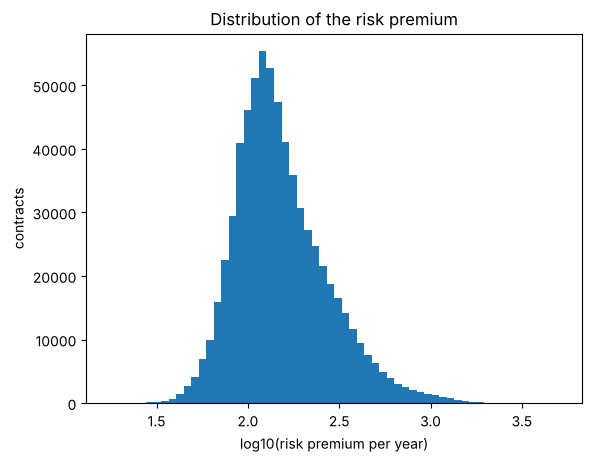

In [13]:
# risk premium of every customer: expected capped claim cost for one full year x large-claim loading
df["RiskPremium"] = predict(glm, df) * loading
print(df["RiskPremium"].describe().round(2))
print("exposure-weighted average:", round(np.average(df["RiskPremium"], weights=df["Exposure"]), 2),
      "| actual cost per contract-year (all data):", round(df["ClaimAmount"].sum() / df["Exposure"].sum(), 2))

cols = ["IDpol", "DrivAge", "BonusMalus", "VehAge", "VehPower", "Area", "Region", "VehBrand", "VehGas", "RiskPremium"]
print(df.loc[[df["RiskPremium"].idxmin(), df["RiskPremium"].idxmax()], cols])

plt.hist(np.log10(df["RiskPremium"]), bins=60)
plt.xlabel("log10(risk premium per year)")
plt.ylabel("contracts")
plt.title("Distribution of the risk premium")
plt.show()

df[["IDpol", "split", "RiskPremium"]].to_parquet("../data/premiums.parquet")

**Findings**

* `RiskPremium` is the expected claim cost of a customer for one full year: the capped GLM prediction × the large-claim
  loading 1.2573. It is the basis of a fair premium; costs, profit margin and taxes would come on top.
* It ranges from 17.30 to 5,084.47 per year; the median is 138.48. The cheapest customer is 33 years old with
  Bonus-Malus 50 and a 21-year-old car with power 4 in area A. The most expensive one is 19 years old with Bonus-Malus
  125 and a 9-year-old Diesel car of brand B11 with power 10 in area D.
* Weighted by exposure, the average premium is 173.09, against an actual cost of 167.18 per contract-year in the whole
  portfolio. The difference comes from the loading: the training part has relatively more large-claim cost (1.2573)
  than the whole portfolio (1.215, step 2).
* The premiums are saved in `data/premiums.parquet` (`IDpol`, `split`, `RiskPremium`).

## 8. Wie könnte man das Modell weiter verbessern? (nicht umgesetzt)

1. **Learn from the GBM:** the GBM is more accurate in every fold of step 3. Comparing its predictions with those of
   the GLM by group (for example age × Bonus-Malus, which are correlated) shows which interactions or finer shapes the
   GLM misses. They can be added to the GLM as terms and checked with the same cross-validation.
2. **Credibility for small groups:** the factors of small regions and brands (R21: 62 claims) are uncertain. A
   penalised GLM (`alpha` > 0, chosen by cross-validation) pulls them towards the average; statistically this is an
   empirical Bayes estimate. The uncertainty of every factor can also be shown directly (standard errors or bootstrap).
3. **Large claims:** the loading rests on 36 claims of the training part and differs strongly between the training and
   the test part (1.2573 against 1.0458). Better: several years of data, a separate model for large claims (how often,
   how large), and a check of the cap (for example 50,000 or 200,000) with the same cross-validation.
4. **Cheapest customers:** the cheapest tenth is too cheap (step 3: GLM 1.19). Finer bands or additional features could
   be checked for this group.
5. **Smoother tariff:** factors that should be monotone (Bonus-Malus 81–90 lies slightly below 71–80) can be made
   monotone by merging bands.
6. **More data:** several years would allow a split by time (fit on the older years, test on the latest year) and
   taking claims inflation into account; features such as the annual mileage would separate the risks further.

## 9. Grenzen

* **One year of data:** training and test part are random samples of the same year; how well the model works for the
  next year is not tested.
* **Claims without an amount:** 9,116 contracts declare claims without any claim amount (step 1). The model uses only
  claims with an amount; if these were real claims whose amounts are missing, the premium level would be too low.
* **Large-claim loading:** one uniform factor for everybody, estimated from few claims (section 2).
* **Cheapest customers:** too cheap in the cross-validation of step 3 and on the test part.
* **No tuning:** the GBM settings are fixed; with other settings its calibration by group might be better (not tested).
* **Small groups:** the test part has too few claims in small groups (for example drivers 18–20) to confirm the
  calibration found in step 3.

## 10. Zusammenfassung

* **Final model:** Poisson × Gamma GLM on claims capped at 100,000, fitted on the training part, times the large-claim
  loading 1.2573.
* **Quality on the test part:** D² 4.78 % (capped claims), Gini 0.313, predicted / actual 1.003. The GBM benchmark is
  slightly more accurate (D² 5.56 %; 95 % bootstrap interval of the deviance difference 0.045 to 1.154), a small price
  for a transparent and better calibrated tariff.
* **Fairness:** in the cross-validation of step 3 every band of the four checked variables was within ±2.5 %, except
  vehicle age 20+ (1.059); on the test part there
  are deviations in small groups, which the GBM shows as well (sample effects, mostly claim sizes).
* **Relevant variables:** Bonus-Malus ≫ driver age > vehicle age > area ≈ region > vehicle power > fuel; brand without
  a measurable effect on the test part.
* **Relationships:** Bonus-Malus factor up to 8.67, youngest drivers 1.96 (mostly larger claims), older vehicles
  cheaper (0.50 for 20+ years), areas D and E the most expensive (1.22 and 1.28).
* **Premium:** risk premium per customer and year from 17.30 to 5,084.47 (median 138.48), saved in `data/premiums.parquet`.
* **Next steps:** learn interactions from the GBM, credibility for small groups, a large-claim model, more years.